# Minjae Kyung CS373 Final Project

The goal of this project is to create a model that generates a portfolio for given stock items by identifying stock volatility using stock data, news data, and major news data. To achieve this, the model is constructed using Transformers and PPO to understand past time series, and is designed to act and evaluate itself using this understanding to obtain better results.

## Import Modules

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import ast
from stable_baselines3 import PPO

from source.stock_portfolio_env import PortfolioEnv
from source.portfolio_feature_extractor import PortfolioFeatureExtractor
from stable_baselines3.common.logger import configure

%load_ext autoreload
%autoreload 1
%aimport source.stock_portfolio_env
%aimport source.portfolio_feature_extractor

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Data Preparation

The project's database file was too large and caused errors on Moodle, so I uploaded it to Google Drive. Please download the files and place them in the root folder.

[Download link](https://drive.google.com/file/d/1NjX8_eeFNrxxvlRJkpbVOmryylncdZVS/view?usp=drive_link)

First, to generate data, stock information of a specific company was collected using the yfinance module. Then, links to data related to the stock's keywords were retrieved using GDELT's DOC 2.0 API. The content from these links was crawled, and the content data was embedded using Gemini-embedding to prepare the data.

As mentioned in the presentation, due to significant difficulties in obtaining data, I will proceed with this project using only Apple's data for this experiment.

The training period will be from 2017-01-04 to 2024-12-31, for which I could obtain data, and the test period will be set to 2025-03-23, up to which global news was most recently available.

In [9]:
DATE_FULL_SLICE = slice("2017-01-04", "2025-03-20")
DATE_TRAIN_SLICE = slice("2017-01-04", "2024-12-31")
DATE_TEST_SLICE = slice("2025-01-01", "2025-03-20")

## Stock Market Data

First, I will refine the stock data obtained through yfinance.

In [10]:
# header=[0, 1]: Use both the first and second rows as column names (header)
apple_stock_df = pd.read_csv('./data_stocks/AAPL_stock.csv', header=[0, 1], index_col=0)

# Remove 'Date' row and if the first row immediately after reading is all NaN, remove it.
if apple_stock_df.iloc[0].isnull().all():
    apple_stock_df = apple_stock_df.iloc[1:]

# Convert index to datetime format
apple_stock_df.index = pd.to_datetime(apple_stock_df.index)

display(apple_stock_df.head())

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
1995-12-08,0.295225,0.295225,0.283978,0.290538,141355200
1995-12-11,0.289601,0.297099,0.287727,0.296162,111652800
1995-12-12,0.284915,0.289601,0.284915,0.289601,177553600
1995-12-13,0.287727,0.292412,0.275543,0.286789,684902400
1995-12-14,0.286790,0.295225,0.284915,0.291475,333502400


Since information before 2017, for which news information is currently available, cannot be used to train the model I designed, I will filter for data from 2017 onwards.

In [11]:
apple_stock_df = apple_stock_df.loc['2017':]
apple_stock_df

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2017-01-03,26.770884,26.812371,26.450509,26.690214,115127600
2017-01-04,26.740919,26.853858,26.678689,26.701737,84472400
2017-01-05,26.876911,26.934533,26.692522,26.717876,88774400
2017-01-06,27.176537,27.234158,26.844637,26.916087,127007600
2017-01-09,27.425461,27.526875,27.183452,27.185756,134247600
...,...,...,...,...,...
2025-11-21,271.489990,273.329987,265.670013,265.950012,59030800
2025-11-24,275.920013,277.000000,270.899994,270.899994,65585800


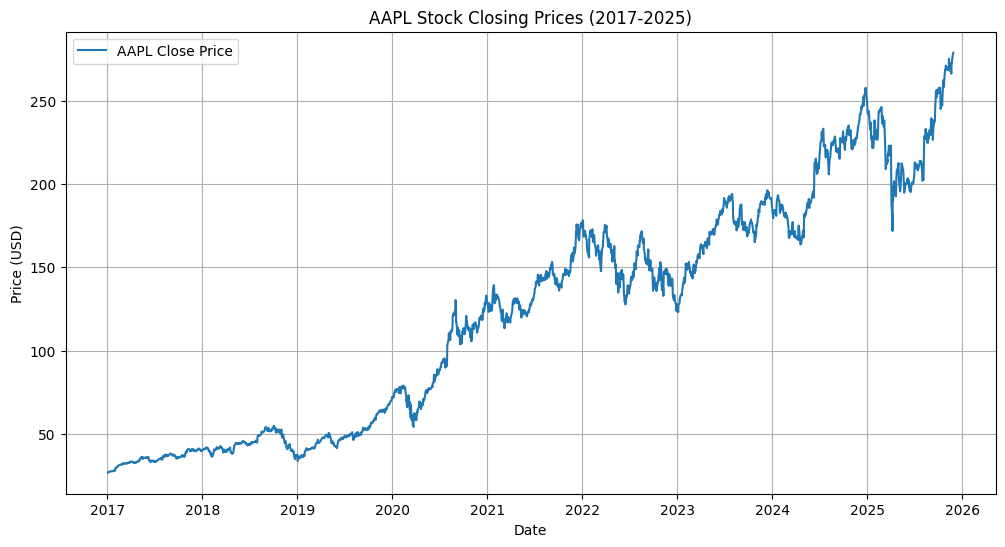

In [12]:
# Plot the closing prices
plt.figure(figsize=(12, 6))
plt.plot(apple_stock_df.index, apple_stock_df[('Close', 'AAPL')], label='AAPL Close Price')
plt.title('AAPL Stock Closing Prices (2017-2025)')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.grid()
plt.show()

As expected of Apple. It has grown tremendously over a period of about eight years. I am concerned that this growth curve might lead the model to learn to unconditionally put all the money into Apple.

And I will transform the values so that the ML model can better understand this stock information.

In [13]:
close_prev = apple_stock_df["Close"].shift(1)
volume_prev = apple_stock_df["Volume"].shift(1)
eps = 1e-8  # Prevent division errors with a small constant

apple_stock_refined_df =  pd.DataFrame(index=apple_stock_df.index)

# 1. Log return of close price relative to previous day's close
apple_stock_refined_df["ret_close"] = np.log((apple_stock_df["Close"] + eps) / (close_prev + eps))

# 2. Open gap relative to previous day's close
apple_stock_refined_df["gap"] = np.log((apple_stock_df["Open"] + eps) / (close_prev + eps))

# 3. Intraday return (Close relative to Open)
apple_stock_refined_df["intraday_ret"] = np.log((apple_stock_df["Close"] + eps) / (apple_stock_df["Open"] + eps))

# 4. High/Low range
apple_stock_refined_df["hl_range"] = np.log((apple_stock_df["High"] + eps) / (apple_stock_df["Low"] + eps))

# 5. Close position between High and Low (0~1)
apple_stock_refined_df["close_pos"] = (apple_stock_df["Close"] - apple_stock_df["Low"]) / (apple_stock_df["High"] - apple_stock_df["Low"] + eps)

# 6. Log volume
apple_stock_refined_df["log_volume"] = np.log(apple_stock_df["Volume"] + 1.0)

# 7. Volume change rate (log ratio)
apple_stock_refined_df["vol_change"] = np.log((apple_stock_df["Volume"] + 1.0) / (volume_prev + 1.0))

Due to this transformation, NaN values have appeared in the very first row, making it unusable, so I will remove it. This is the reason why the start date of our data was determined.

In [14]:
apple_stock_refined_df = apple_stock_refined_df.dropna()
apple_stock_refined_df = apple_stock_refined_df.loc[DATE_FULL_SLICE]
apple_stock_refined_df

,ret_close,gap,intraday_ret,hl_range,close_pos,log_volume,vol_change
Date,,,,,,,
2017-01-04,-0.001120,-0.002586,0.001466,0.006544,0.355258,18.251935,-0.309616
2017-01-05,0.005073,-0.000862,0.005935,0.009026,0.761905,18.301609,0.049673
2017-01-06,0.011086,0.001457,0.009630,0.014406,0.852071,18.659757,0.358149
2017-01-09,0.009118,0.000339,0.008779,0.012554,0.704696,18.715196,0.055439
2017-01-10,0.001008,-0.001851,0.002859,0.009088,0.750002,18.398930,-0.316267
...,...,...,...,...,...,...,...
2025-03-14,0.018007,0.007460,0.010548,0.020637,0.894739,17.911647,-0.020757
2025-03-17,0.002386,-0.000844,0.003230,0.024696,0.767619,17.688240,-0.223407
2025-03-18,-0.006140,0.000747,-0.006888,0.017158,0.327869,17.563423,-0.124817


Now, I will split this data based on time: data before 2025 for training, and data from 2025 for testing.

In [15]:
apple_stock_train = np.array(apple_stock_refined_df.loc[DATE_TRAIN_SLICE])
apple_close_prices_train = np.array(apple_stock_df.loc[DATE_TRAIN_SLICE]["Close"])

apple_stock_test = np.array(apple_stock_refined_df.loc[DATE_TEST_SLICE])
apple_close_prices_test = np.array(apple_stock_df.loc[DATE_TEST_SLICE]["Close"])

In [16]:
print("Train shape:", apple_stock_train.shape)
print(apple_stock_train)

print("Test shape:", apple_stock_test.shape)
print(apple_stock_test)

Train shape: (2011, 7)
[[-1.11991929e-03 -2.58624269e-03  1.46632340e-03 ...  3.55257722e-01
   1.82519354e+01 -3.09616222e-01]
 [ 5.07265367e-03 -8.62102879e-04  5.93475655e-03 ...  7.61905422e-01
   1.83016089e+01  4.96734658e-02]
 [ 1.10863776e-02  1.45653734e-03  9.62984024e-03 ...  8.52071198e-01
   1.86597575e+01  3.58148604e-01]
 ...
 [-1.33305987e-02 -4.60478152e-03 -8.72581715e-03 ...  4.48580178e-01
   1.75616041e+01  4.41513533e-01]
 [-1.33521898e-02 -1.32332485e-02 -1.18941299e-04 ...  5.27271616e-01
   1.73866617e+01 -1.74942452e-01]
 [-7.08286317e-03  9.51242290e-04 -8.03410546e-03 ...  2.57143876e-01
   1.74913225e+01  1.04660838e-01]]
Test shape: (53, 7)
[[-2.65862312e-02 -5.96783539e-03 -2.06183958e-02  2.96607687e-02
   2.78846033e-01  1.78362212e+01  3.44898628e-01]
 [-2.01151309e-03 -2.01151309e-03  0.00000000e+00  9.42255340e-03
   6.41923810e-01  1.75104740e+01 -3.25747164e-01]
 [ 6.71649963e-03  3.89618980e-03  2.82030983e-03  1.68393472e-02
   4.35835574e-01  1.

And since I might use the refined data later, I will save it for now.

In [17]:
apple_stock_refined_df.to_csv('./data_stocks/AAPL_stock_refined.csv')

### Apple Stock News Data

Now, I will load the news data to be used for analyzing this Apple stock.

In [18]:
apple_stock_news_df = pd.read_csv('./data_news_pipeline/step2_content/AAPL_content.csv', index_col=0)
apple_stock_news_df_cleaned = apple_stock_news_df[~apple_stock_news_df.isna().any(axis=1)] # Remove rows with missing values
apple_stock_news_df_cleaned.index = pd.to_datetime(apple_stock_news_df_cleaned.index) # Convert index to datetime format
apple_stock_news_df_cleaned = apple_stock_news_df_cleaned.sort_index() # Sort by index
apple_stock_news_df_cleaned = apple_stock_news_df_cleaned[:"2025-11-01"] # Filter data up to 2025-11-01

In [19]:
apple_stock_news_df_cleaned

,Title,Media,Link,FullText
Date,,,,
2017-01-01,"Nwam LLC Has $8 , 159 , 000 Stake in Apple Inc...",mideasttime.com,http://www.mideasttime.com/nwam-llc-has-815900...,Menelusuri dunia situs game online terpercaya ...
2017-01-02,APPLE IPHONE 7 PLUS 256GB,mouthshut.com,http://www.mouthshut.com/review/Apple-iPhone-7...,Iphone is a line of smart phone design and mar...
2017-01-02,Apple partner Wistron seeks to expand India sm...,thestar.com.my,http://www.thestar.com.my/business/business-ne...,MUMBAI: Smartphone component maker Wistron Cor...
2017-01-02,Apple partner Wistron seeks to expand India sm...,otcstockexchange.com,http://otcstockexchange.com/apple-partner-wist...,Acquiring OakvilleMaids.com through HugeDomain...
2017-01-02,Apple Inc . ( NASDAQ : AAPL ) Broker Price Tar...,fiscalstandard.com,http://www.fiscalstandard.com/2017/01/02/apple...,Name Properties\n\nLength 14\n\nTLD com\n\nReg...
...,...,...,...,...
2025-10-31,Jim Cramer Says Apple Bears Owe Us An Explana...,benzinga.com,https://www.benzinga.com/markets/tech/25/10/48...,"On Thursday, Apple Inc. (NASDAQ:AAPL) delivere..."
2025-10-31,Los Altos history : See the 1905 J . Gilbert S...,mercurynews.com,https://www.mercurynews.com/2025/10/31/los-alt...,If time travel were possible and you were zapp...
2025-11-01,Big Tech stubborn winning streak seems to be h...,latimes.com,https://www.latimes.com/business/story/2025-10...,A record-smashing rally in megacap high-fliers...


And I will check if the news is well distributed by date.

#### Check Data

In [20]:
daily_counts = apple_stock_news_df_cleaned.resample('D').size()

print(daily_counts.describe())

count    3227.000000
mean       14.428881
std        12.949499
min         0.000000
25%         5.000000
50%        12.000000
75%        21.000000
max       242.000000
dtype: float64


Looking at the describe output, apart from a strange maximum value of 242, it seems relatively well distributed from 25% to 75%. I will draw a histogram to see it in more detail.

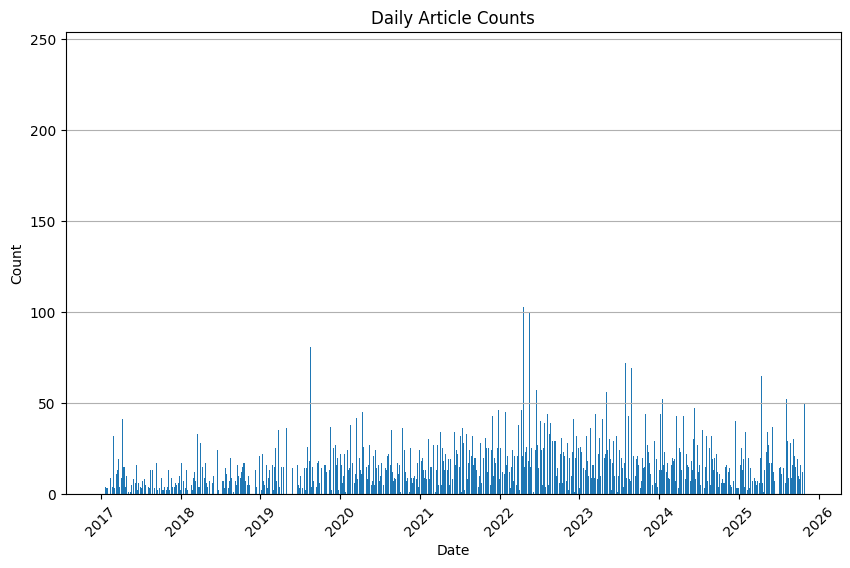

In [21]:
# 1. Get counts by date
daily_counts = apple_stock_news_df_cleaned.index.value_counts().sort_index()

# 2. Draw graph
plt.figure(figsize=(10, 6))  # Set graph size (width, height)
plt.bar(daily_counts.index, daily_counts.values)

# 3. Decoration (Optional)
plt.title('Daily Article Counts') # Title
plt.xlabel('Date')                # x-axis label
plt.ylabel('Count')               # y-axis label
plt.xticks(rotation=45)           # Rotate 45 degrees to prevent date overlap
plt.grid(axis='y')                # Add y-axis grid lines

plt.show()

Fortunately, it seems to be evenly distributed. The protagonist with 242 counts is too thin to be seen, but it seems fine to proceed without further refinement. Since I will be calculating the average of embeddings anyway, a large difference in counts shouldn't matter much.

Now, I will proceed with embedding in make_embedding.py and then load the csv again.

In [22]:
apple_stock_news_embedded_df = pd.read_csv('./data_news_pipeline/step4_embedding/AAPL_embedded.csv', index_col=0)
apple_stock_news_embedded_df.index = pd.to_datetime(apple_stock_news_embedded_df.index) # Convert index to datetime format
apple_stock_news_embedded_df = apple_stock_news_embedded_df.sort_index() # Sort by index

apple_stock_news_embedded_df.index = pd.to_datetime(apple_stock_news_embedded_df.index) # Convert index to datetime format

apple_stock_news_embedded_df["embedding"] = apple_stock_news_embedded_df["embedding"].apply(ast.literal_eval) # Convert embedding vectors stored as strings to lists
apple_stock_news_embedded_df.head()

,Title,Media,Link,FullText,embedding
Date,,,,,
2017-01-01,"Nwam LLC Has $8 , 159 , 000 Stake in Apple Inc...",mideasttime.com,http://www.mideasttime.com/nwam-llc-has-815900...,Menelusuri dunia situs game online terpercaya ...,"[-0.012577439, -0.024079252, 0.0044829804, -0...."
2017-01-02,APPLE IPHONE 7 PLUS 256GB,mouthshut.com,http://www.mouthshut.com/review/Apple-iPhone-7...,Iphone is a line of smart phone design and mar...,"[-0.017085219, -0.00029014514, 0.010020777, -0..."
2017-01-02,Apple partner Wistron seeks to expand India sm...,thestar.com.my,http://www.thestar.com.my/business/business-ne...,MUMBAI: Smartphone component maker Wistron Cor...,"[-0.013036417, 0.005417432, -0.0069397204, -0...."
2017-01-02,Apple partner Wistron seeks to expand India sm...,otcstockexchange.com,http://otcstockexchange.com/apple-partner-wist...,Acquiring OakvilleMaids.com through HugeDomain...,"[-0.02031213, -0.0048704566, 0.00731049, -0.04..."
2017-01-02,Apple Inc . ( NASDAQ : AAPL ) Broker Price Tar...,fiscalstandard.com,http://www.fiscalstandard.com/2017/01/02/apple...,Name Properties\n\nLength 14\n\nTLD com\n\nReg...,"[-0.025122736, -0.0029164955, 0.00968244, -0.0..."


Now, I will group the embedded data by date and calculate the average of the group to use as data. If there is no data, I filled it with a zero vector to represent the absence of data.

In [23]:
apple_stock_news_daily_embedded_df = apple_stock_news_embedded_df.groupby(apple_stock_news_embedded_df.index)["embedding"].apply(
    lambda x: np.mean(np.stack(x.to_list()), axis=0)
)

apple_stock_news_daily_embedded_df = apple_stock_news_daily_embedded_df.reindex(apple_stock_refined_df.index, fill_value=np.zeros(768, dtype=float))

In [24]:
apple_stock_news_daily_embedded_df

Date
2017-01-04    [0.0002958253428571428, 0.008216654488571428, ...
2017-01-05    [-0.002357274371428572, 0.00839291867857143, 0...
2017-01-06    [-0.004536945200000001, 0.009776788659999999, ...
2017-01-09    [-0.004417279499999999, 0.014180763733333332, ...
2017-01-10    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...
                                    ...                        
2025-03-14    [0.005105511300000001, 0.007574836036363638, -...
2025-03-17    [-0.007670697607142857, 0.0044955320071428575,...
2025-03-18    [-0.0019257603714285716, 0.0035718402714285708...
2025-03-19    [-0.00553735875, -0.005747633325, -0.000700041...
2025-03-20    [-0.005589289344999999, 0.004117237437499999, ...
Name: embedding, Length: 2064, dtype: object

Now, I will split this prepared data into train and test sets.

In [25]:
apple_stock_news_train = np.array(apple_stock_news_daily_embedded_df.loc[DATE_TRAIN_SLICE].to_list())
apple_stock_news_test = np.array(apple_stock_news_daily_embedded_df.loc[DATE_TEST_SLICE].to_list())

In [26]:
print("Train shape:", apple_stock_news_train.shape)
print(apple_stock_news_train)

print("Test shape:", apple_stock_news_test.shape)
print(apple_stock_news_test)

Train shape: (2011, 768)
[[ 0.00029583  0.00821665  0.00638967 ... -0.00303317  0.01598059
   0.00275139]
 [-0.00235727  0.00839292  0.00425965 ...  0.00235728  0.03211411
   0.01759749]
 [-0.00453695  0.00977679  0.01009204 ... -0.00232958  0.02709207
   0.00097309]
 ...
 [-0.00490118  0.00831638 -0.00797129 ...  0.00269107  0.02998972
  -0.00563032]
 [ 0.00729869 -0.01176972 -0.01924924 ... -0.0034694   0.04175829
   0.00454587]
 [-0.00116139  0.00228404 -0.01335437 ...  0.00070454  0.02399433
  -0.00964598]]
Test shape: (53, 768)
[[-0.0097006  -0.00320553 -0.00580521 ... -0.01334509  0.03574609
  -0.00182497]
 [-0.01084565  0.00015118 -0.00657774 ... -0.00687673  0.03845683
   0.00170672]
 [-0.00212003  0.01076652 -0.01085851 ... -0.00655631  0.03629475
   0.00305249]
 ...
 [-0.00192576  0.00357184 -0.00565923 ...  0.0032003   0.02094969
   0.00215991]
 [-0.00553736 -0.00574763 -0.00070004 ...  0.01299353  0.01000328
  -0.00230053]
 [-0.00558929  0.00411724 -0.00105955 ... -0.009977

Now, I will load, refine, and embed the data of major news obtained through GDELT.

In [27]:
# Load global news embedding df
main_news_df = pd.read_csv("./main_news/main_news.csv", index_col=0)
main_news_df.index = pd.to_datetime(main_news_df.index)

In [28]:
# 2. Remove duplicates based on Title (keep only the first one)
main_news_df_cleaned= main_news_df.drop_duplicates(subset="Title", keep="first")

# 3. Remove rows where Title length is 20 characters or less
main_news_df_cleaned = main_news_df_cleaned[main_news_df_cleaned["Title"].str.len() > 40]


main_news_df_cleaned = main_news_df_cleaned.sort_index()

main_news_df_cleaned

,Theme,Keyword,Title,Media,Link
Date,,,,,
2017-01-01,Politics_and_Diplomacy,Nationalism,2017 a year of Transition from Globalization t...,dailymirror.lk,http://www.dailymirror.lk/article/-a-year-of-T...
2017-01-01,Society_and_Culture,Body Match/Other,Rampell : American voters believe crazy things,trib.com,http://trib.com/opinion/columns/rampell-americ...
2017-01-01,Society_and_Culture,Body Match/Other,"Rampell : Americans believe crazy , wrong things",burlingtonfreepress.com,http://www.burlingtonfreepress.com/story/opini...
2017-01-01,Society_and_Culture,Body Match/Other,Catherine Rampell : Its not just Trump voters ...,sltrib.com,http://www.sltrib.com/opinion/4765832-155/cath...
2017-01-01,Society_and_Culture,Conspiracy Theory,Conspiracy theory ’ s big comeback : Deep para...,salon.com,http://www.salon.com/2017/01/01/conspiracy-the...
...,...,...,...,...,...
2025-03-29,Politics_and_Diplomacy,Genocide,Arab Failures : The Unspoken Complicity In Isr...,kashmirreader.com,https://kashmirreader.com/2025/03/30/arab-fail...
2025-03-29,Politics_and_Diplomacy,Body Match/Other,Why Vladimir Putin is afraid of sea cucumbers,spectator.co.uk,https://www.spectator.co.uk/article/why-vladim...
2025-03-29,Politics_and_Diplomacy,Body Match/Other,Palestine accuses Israel of backing settler c...,biztoc.com,https://biztoc.com/x/74cf82fbc7822655


Currently, there is too much data collected from main news, so embedding takes too long. I will apply a stronger filter and randomly select and save only 5 items per theme for each date.

In [29]:
main_news_df_zipped = main_news_df_cleaned[main_news_df_cleaned["Title"].str.len() > 80]
main_news_df_zipped = (
    main_news_df_cleaned.groupby(['Date', 'Theme'], group_keys=False)
      .apply(lambda g: g.sample(n=min(len(g), 5), random_state=42))
)

main_news_df_zipped.sample(10)

C:\Users\sanea\AppData\Local\Temp\ipykernel_50368\2944223076.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(n=min(len(g), 5), random_state=42))


,Theme,Keyword,Title,Media,Link
Date,,,,,
2017-10-18,Environment_and_Energy,Body Match/Other,Sask . Party leadership hopeful Gordon Wyant b...,estevanmercury.ca,http://www.estevanmercury.ca/news/local-news/s...
2023-04-28,Economy_and_Market,Inflation,Pakistan approves up to 20 % rise in drug pric...,marketscreener.com,https://www.marketscreener.com/news/latest/Pak...
2018-09-03,Politics_and_Diplomacy,Populism,Are younger voters really the best defence aga...,prospectmagazine.co.uk,http://www.prospectmagazine.co.uk/world/are-yo...
2024-09-07,Technology_and_Science,Body Match/Other,"Meredith Whittaker of Signal , disinformation ...",rappler.com,https://www.rappler.com/moveph/social-good-sum...
2021-06-23,Technology_and_Science,Machine Learning,Machine learning for solar energy is supercomp...,eurekalert.org,https://www.eurekalert.org/pub_releases/2021-0...
2023-07-09,Society_and_Culture,Digital Nomad,7 Websites to Help You Choose the Right Destin...,makeuseof.com,https://www.makeuseof.com/websites-to-choose-d...
2019-05-31,Environment_and_Energy,Fossil Fuels,Energy Secretary : US Aims to Make Fossil Fuel...,voanews.com,https://www.voanews.com/a/energy-secretary-us-...
2024-08-12,Economy_and_Market,Body Match/Other,We Said Dont Panic ; It Seems Markets Didnt Li...,nasdaq.com,https://www.nasdaq.com/articles/we-said-dont-p...
2021-11-19,Society_and_Culture,Brain Drain,Nigeria : Brain Drain Hits Radiography Profess...,allafrica.com,https://allafrica.com/stories/202111190526.html


And again, I will save it as csv and proceed with embedding using make_embedding.py.

In [30]:
main_news_df_zipped.to_csv("./main_news/main_news_zipped.csv")

In [31]:
main_news_embedded_df = pd.read_csv('./main_news/main_news_zipped_embedded.csv', index_col=0)
main_news_embedded_df.index = pd.to_datetime(main_news_embedded_df.index)
main_news_embedded_df = main_news_embedded_df.sort_index()

main_news_embedded_df.index = pd.to_datetime(main_news_embedded_df.index)

main_news_embedded_df["embedding"] = main_news_embedded_df["embedding"].apply(ast.literal_eval)
main_news_embedded_df

,Theme,Keyword,Title,Media,Link,embedding
Date,,,,,,
2017-01-01,Economy_and_Market,Recession,Recession would only end if 85 % of budget imp...,dailytrust.com.ng,http://www.dailytrust.com.ng/news/feature/rece...,"[0.020393016, -0.0007736065, 0.0061083655, -0...."
2017-01-01,Economy_and_Market,Body Match/Other,Finland Discovers The Standard Keynesian Reaso...,forbes.com,http://www.forbes.com/sites/timworstall/2016/0...,"[0.0022445126, 0.022903226, -0.0063515278, -0...."
2017-01-01,Economy_and_Market,Body Match/Other,Extending fiscal contingency steps may break EU,dawn.com,http://www.dawn.com/news/1305684,"[0.009758994, 0.014293156, -0.0033957034, -0.0..."
2017-01-01,Economy_and_Market,Bailout,Who Exactly Benefits from Italy Ballooning Ban...,straightlinelogic.com,https://straightlinelogic.com/2016/12/31/who-e...,"[0.012180764, 0.011198881, 0.015930383, -0.086..."
2017-01-01,Economy_and_Market,Private Equity,How you can earn over $200k in the back office...,news.efinancialcareers.com,http://news.efinancialcareers.com/dk-en/269560...,"[-0.013298475, 0.0003291452, 0.0014957831, -0...."
...,...,...,...,...,...,...
2025-03-29,Politics_and_Diplomacy,Body Match/Other,Articles By Vedant Chandel | The Tribune : Tod...,tribuneindia.com,https://www.tribuneindia.com/author/vedant-cha...,"[0.003688396, -0.0042639524, 0.003512848, -0.0..."
2025-03-29,Politics_and_Diplomacy,Sovereign Debt,"Modern Wealth Management LLC Invests $260 , 00...",themarketsdaily.com,https://www.themarketsdaily.com/2025/03/29/mod...,"[-0.029383872, 0.009554428, -0.007373179, -0.0..."
2025-03-29,Politics_and_Diplomacy,Body Match/Other,Human Appeal Mobilizes 13 thousand Food & Shel...,finanznachrichten.de,https://www.finanznachrichten.de/nachrichten-2...,"[-0.019827988, -0.014824159, 0.0071620457, -0...."


Like Apple's news, I will now group each vector by date to calculate the average, filter according to the stock dates, and fill in empty values.

In [32]:
main_news_daily_embedded_df = main_news_embedded_df.groupby(main_news_embedded_df.index)["embedding"].apply(
    lambda x: np.mean(np.stack(x.to_list()), axis=0)
)

main_news_daily_embedded_df = main_news_daily_embedded_df.reindex(apple_stock_refined_df.index, fill_value=np.zeros(768, dtype=float))
main_news_daily_embedded_df

Date
2017-01-04    [-0.005351506516000002, 0.00341402783228, 0.00...
2017-01-05    [-0.0002250890232000002, 0.0054552469328, 0.00...
2017-01-06    [-0.008119248635200001, 0.002119885884, 0.0055...
2017-01-09    [-0.0027022650302, 0.0082183750952, 0.00886820...
2017-01-10    [-0.003106977788, 0.0045593599852, 0.003986926...
                                    ...                        
2025-03-14    [-0.0055360869407999995, -0.000689291952, -9.5...
2025-03-17    [-0.0044676043200000005, 0.003525745952, 0.004...
2025-03-18    [-0.0028136684350000005, 0.01126102782, -0.000...
2025-03-19    [-0.0003584563359999994, 0.005634270791999999,...
2025-03-20    [-0.0018156737976190473, 0.0031845851666666676...
Name: embedding, Length: 2064, dtype: object

Now, I will split this data into train and test sets.

In [33]:
main_news_train = np.array(main_news_daily_embedded_df.loc[DATE_TRAIN_SLICE].to_list())
main_news_test = np.array(main_news_daily_embedded_df.loc[DATE_TEST_SLICE].to_list())

In [34]:
print("Train shape:", main_news_train.shape)
print(main_news_train)

print("Test shape:", main_news_test.shape)
print(main_news_test)

Train shape: (2011, 768)
[[-0.00535151  0.00341403  0.00736377 ... -0.00355054  0.04990505
   0.00602833]
 [-0.00022509  0.00545525  0.0045534  ... -0.00689097  0.04696792
   0.00343611]
 [-0.00811925  0.00211989  0.0055735  ... -0.00361236  0.04465124
   0.00179183]
 ...
 [-0.00309703  0.00610305  0.00109272 ...  0.00090718  0.04596446
   0.00347826]
 [-0.00120092  0.00580332  0.0038981  ... -0.00486115  0.04413419
   0.0011056 ]
 [-0.00434124  0.00245715 -0.00069369 ... -0.0036459   0.04019304
   0.00227437]]
Test shape: (53, 768)
[[-1.34657777e-03  2.13087569e-03  8.20630767e-04 ...  9.56222740e-04
   4.51392655e-02  4.46740104e-03]
 [-1.57999793e-03  8.76525080e-03  9.27111252e-04 ... -1.77299776e-03
   4.57547794e-02  4.81182282e-03]
 [-7.80985600e-04  6.97726477e-03  3.08397790e-03 ... -3.11063668e-03
   4.67423240e-02 -7.19113447e-04]
 ...
 [-2.81366844e-03  1.12610278e-02 -4.06201898e-04 ... -6.85768942e-03
   4.39696782e-02  7.88701061e-03]
 [-3.58456336e-04  5.63427079e-03  2

## Machine Leaning Model Implemetation

Since the structure of the learning algorithm I implemented is complex, I implemented it separately in another Python file instead of writing it in the Jupyter Notebook.

To explain the overall structure, it is largely divided into 3 steps:
- First, each stock is analyzed through two attentions. One analyzes the stock graph itself through self-attention, and the second analyzes the stock through cross-attention by setting the stock as Q and the embedded news as K.
- Then, the encoded features of the stocks derived from this are analyzed again through attention. At this time, global news is also encoded as a feature and input together with the encoded features. Here, self-attention is used instead of cross-attention, so that the elements of the resulting vector represent the score of the stock itself.
- Finally, I created two NNs that take the resulting features and output respective results, taking the form of actor and critic to enable RL.

Detailed code structure can be found by checking the portfolio_feature_extractor, stock news_backbone, and stock_portfolio_env files in the source folder.

Now, I will resize the refined data to fit the model I designed. Since there is currently only Apple data, I added a dimension to that data, and for the close prices to be used for evaluation, I created an array consisting of 1s to represent cash as well as Apple data.

In [35]:
stock_feat_train = apple_stock_train[:, np.newaxis, :]
stock_feat_test = apple_stock_test[:, np.newaxis, :]

stock_news_train = apple_stock_news_train[:, np.newaxis, :]
stock_news_test =apple_stock_news_test[:, np.newaxis, :]

stock_close_prices_train = np.concat([apple_close_prices_train, np.ones_like(apple_close_prices_train)], axis=1)
stock_close_prices_test = np.concat([apple_close_prices_test, np.ones_like(apple_close_prices_test)], axis=1)

In [36]:
print("Stock feature shape:", stock_feat_train.shape)
print("Stock news shape:", stock_news_train.shape)
print("Main news shape:", main_news_train.shape)

Stock feature shape: (2011, 1, 7)
Stock news shape: (2011, 1, 768)
Main news shape: (2011, 768)


Now I will configure the environment and model I designed. First, I will design the Gymnasium environment and then put it into the Stable Baselines3 PPO model along with the portfolio model I designed so that PPO can learn.

In [37]:
WINDOW_SIZE = 50

env = PortfolioEnv(
    stock_feat=stock_feat_train,
    stock_news=stock_news_train,
    global_news=main_news_train,
    close_prices=stock_close_prices_train,
    window_size=WINDOW_SIZE,
    trading_cost=0.01,  # 1% commission
)

In [38]:
from source.portfolio_feature_extractor import PortfolioFeatureExtractor

policy_kwargs = dict(
    features_extractor_class=PortfolioFeatureExtractor,
    features_extractor_kwargs=dict(
        d_model=256, # Feature extractor internal embedding dimension
        n_head=4, # Number of heads in multi-head attention
        agent_layers=2, # Number of agent layers
    ),
    # Since the backbone is already complex, keep the head MLP simple:
    net_arch=dict(pi=[64], vf=[64]),
)

model = PPO(
    policy="MultiInputPolicy",
    env=env,
    policy_kwargs=policy_kwargs,
    verbose=1, # Log output level
    seed=42,
    n_steps=2048
)

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


And to save data that can be useful after training, I will save the data using a callback.

In [39]:
from stable_baselines3.common.callbacks import BaseCallback

class DebugCallback(BaseCallback):
    def __init__(self, verbose=0):
        super(DebugCallback, self).__init__(verbose)
        self.infos = []
        self.rewards = []
        self.actions = []

    def _on_step(self) -> bool:
        # Output current status every 100 steps
        if self.n_calls % 100 == 0:
            # Check cumulative reward or actions of the current episode
            infos = self.locals.get("infos", [{}])[0]
            rewards = self.locals.get("rewards", [0])[0]
            actions = self.locals.get("actions", [0])[0]

            self.infos.append(infos)
            self.rewards.append(rewards)
            self.actions.append(actions)
            
        return True

In [40]:
# Training algorithm
# Training takes 5 hours and 20 minutes, so be very careful!!!!

# total_timesteps = 2_000_000
# DebugLogger = DebugCallback()

# model.learn(total_timesteps=total_timesteps, callback=DebugLogger)
# model.save("./models/portfolio_ppo_v1")


Finally, the long training of 508 minutes is complete, and now I will check what happened during the training through the remaining logs.

First, I will load the model to prevent the disaster of having to run this training again.

In [41]:
model = PPO.load("./models/portfolio_ppo_v1")

In [42]:
debug_infos_df = pd.read_csv("./logs/debug_infos.csv")

First, I will draw a graph of the reward to see how the training proceeded.

In [43]:
episode_rewards = debug_infos_df[debug_infos_df['episode.r'].notna()]['episode.r']
episode_rewards.head()

97    -8.518520
195   -8.363483
293   -7.465167
391   -6.764041
489   -5.830368
Name: episode.r, dtype: float64

#### Evaluation

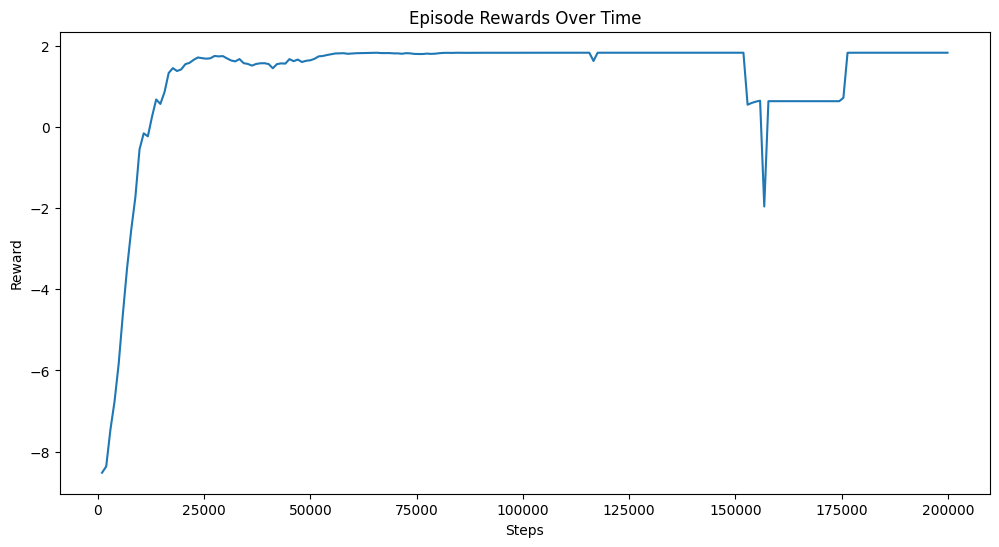

In [44]:
# Plot episode rewards over time
plt.figure(figsize=(12, 6))
plt.plot(episode_rewards.index * 10, episode_rewards.values) # Real step is index * 10
plt.title('Episode Rewards Over Time')
plt.xlabel('Steps')
plt.ylabel('Reward')
plt.show()

Looking at this graph, it learns actively up to 50,000 steps, and the reward value stabilizes around 60,000 steps. Unusually, it can be seen that there is a section where the reward function suddenly drops around 150,000 steps.

Now, I will run the test set with the learned algorithm to see the results. At this time, I will take the last data from the train set as much as the window size and attach it to the front. This has the advantage that data leakage does not occur because the prediction range itself does not overlap between the train set and the test set, and the range of the test set can be further extended.

In [45]:
stock_feat_test_env = np.concatenate(
    [stock_feat_train[-WINDOW_SIZE:], stock_feat_test],
    axis=0
)

# 2) stock_news: (T, N, F_news)
stock_news_test_env = np.concatenate(
    [stock_news_train[-WINDOW_SIZE:], stock_news_test],
    axis=0
)

# 3) main_news: (T, F_macro)
main_news_test_env = np.concatenate(
    [main_news_train[-WINDOW_SIZE:], main_news_test],
    axis=0
)

# 4) close_prices: (T, N)
stock_close_prices_test_env = np.concatenate(
    [stock_close_prices_train[-WINDOW_SIZE:], stock_close_prices_test],
    axis=0
)

In [46]:
print(stock_feat_test_env.shape)
print(stock_news_test_env.shape)
print(main_news_test_env.shape)
print(stock_close_prices_test_env.shape)

(103, 1, 7)
(103, 1, 768)
(103, 768)
(103, 2)


In [47]:

test_env = PortfolioEnv(
    stock_feat=stock_feat_test_env,
    stock_news=stock_news_test_env,
    global_news=main_news_test_env,
    close_prices=stock_close_prices_test_env,
    window_size=WINDOW_SIZE,
    trading_cost=0.01,  # 1% commission
)
obs, info = test_env.reset()
done = False
total_reward = 0.0


while not done:
    action, _ = model.predict(obs, deterministic=True) # If deterministic=True, act according to "policy itself" without exploration
    obs, reward, terminated, truncated, info = test_env.step(action)
    done = terminated or truncated
    total_reward += reward

print("Episode total reward:", total_reward)
print("Final wealth:", info["wealth"])

Episode total reward: -0.1203762
Final wealth: 0.8865869


In the set I just ran, the result was losing the original money. I'm a bit confused as to why. I wonder if the difference would be this big even if it was overfitted, so I'm going to check how the actual stock was.

In [48]:
stock_close_prices_test[-1, 0] / stock_close_prices_test[0, 0]

np.float64(0.8789641159743469)

Through this, it could be seen that it succeeded in defending to some extent while the actual stock was falling, but since the model I want is a model that cashes out when it falls and buys stocks when it rises, it cannot be said to be that satisfactory.

And since the logger I made with callback gives less information than I thought, this time I will set it up in my own logger and train it again.

### Training Second Model

In [49]:
class WealthLoggerCallback(BaseCallback):
    """
    Simple callback to add custom metric ('wealth') to default logger
    """
    def _on_step(self) -> bool:
        # Get info of current environment
        infos = self.locals.get("infos", [{}])[0]
        
        # Record to logger if wealth information exists
        if "wealth" in infos:
            self.logger.record("custom/wealth", infos["wealth"])
            
        return True

In [50]:
from source.portfolio_feature_extractor import PortfolioFeatureExtractor

policy_kwargs = dict(
    features_extractor_class=PortfolioFeatureExtractor,
    features_extractor_kwargs=dict(
        d_model=256,
        n_head=4,
        agent_layers=2,
    ),
    net_arch=dict(pi=[64], vf=[64]),
)

model_v2 = PPO(
    policy="MultiInputPolicy",
    env=env,
    policy_kwargs=policy_kwargs,
    verbose=1,
    seed=42,
    n_steps=2048
)

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


In [51]:
log_path = "./logs/ppo_portfolio_v2"
new_logger = configure(log_path, ["stdout", "csv"])

# 2. Attach logger to model
model_v2.set_logger(new_logger)

Logging to ./logs/ppo_portfolio_v2


This time, I will proceed with learning only up to around 700,000, which is the step that rises to the first plateau confirmed in the previous graph.

In [52]:
# total_timesteps = 700_000
# model_v2.learn(total_timesteps=total_timesteps, callback=WealthLoggerCallback())

# model_v2.save("./models/portfolio_ppo_v2")

Finally, 221 minutes of learning is complete, and to prevent the disaster of having to do this again, I will load the file for evaluation.

In [53]:
model_v2 = PPO.load("./models/portfolio_ppo_v2")

In [54]:

obs, info = test_env.reset()
done = False
total_reward = 0.0


while not done:
    action, _ = model_v2.predict(obs, deterministic=True) # If deterministic=True, act according to "policy itself" without exploration
    obs, reward, terminated, truncated, info = test_env.step(action)
    done = terminated or truncated
    total_reward += reward

print("Episode total reward:", total_reward)
print("Final wealth:", info["wealth"])

Episode total reward: -0.1203762
Final wealth: 0.8865869


Now, perfectly identical results came out. It's an emergency. First, I'll try to figure out what's going on.

In [55]:
# Reset test environment
obs, _ = test_env.reset()

# Predict actions of two models
action_v1, _ = model.predict(obs, deterministic=True)
action_v2, _ = model_v2.predict(obs, deterministic=True)

print(f"Model V1 Raw Action: {action_v1[:5]}") # Print only the beginning
print(f"Model V2 Raw Action: {action_v2[:5]}")

# Softmax transformation (actual investment weight)
def softmax(x):
    e_x = np.exp(x - np.max(x))
    return e_x / e_x.sum()

weight_v1 = softmax(action_v1)
weight_v2 = softmax(action_v2)

print("-" * 30)
print(f"Model V1 Weights: {weight_v1[:5]}")
print(f"Model V2 Weights: {weight_v2[:5]}")


Model V1 Raw Action: [ 1. -1.]
Model V2 Raw Action: [ 1. -1.]
------------------------------
Model V1 Weights: [0.880797   0.11920292]
Model V2 Weights: [0.880797   0.11920292]


What I was worried about has happened. It learned that if you just put stocks in Apple, it will skyrocket unconditionally, so it learned to put as much as possible into Apple. First of all, I thought this might be because the stock commission is too high, so I decided to lower the stock trading commission and train again.

### Train Third Model

This time, I will significantly lower the commission to 0.1% and proceed with the rest with the same weights.

In [56]:
env = PortfolioEnv(
    stock_feat=stock_feat_train,
    stock_news=stock_news_train,
    global_news=main_news_train,
    close_prices=stock_close_prices_train,
    window_size=WINDOW_SIZE,
    trading_cost=0.001,  # 0.1% commission
)

In [57]:
from source.portfolio_feature_extractor import PortfolioFeatureExtractor

policy_kwargs = dict(
    features_extractor_class=PortfolioFeatureExtractor,
    features_extractor_kwargs=dict(
        d_model=256,
        n_head=4,
        agent_layers=2,
    ),
    # Since the backbone is already complex, keep the head MLP simple:
    net_arch=dict(pi=[64], vf=[64]),
)

model_v3 = PPO(
    policy="MultiInputPolicy",
    env=env,
    policy_kwargs=policy_kwargs,
    verbose=1,
    seed=42,
    n_steps=2048
)

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


And to collect better logger information, I will save wealth when the episode ends.

In [58]:
class BetterWealthLoggerCallback(BaseCallback):
    def _on_step(self) -> bool:
        # Get info of current environment
        infos = self.locals.get("infos", [{}])[0]
        
        # Record to logger if wealth information exists
        if "episode" in infos:
            self.logger.record_mean("custom/final_wealth", infos["wealth"])
            
        return True

In [59]:
log_path = "./logs/ppo_portfolio_v3"
new_logger = configure(log_path, ["stdout", "csv"])

# 2. Attach logger to model
model_v3.set_logger(new_logger)

Logging to ./logs/ppo_portfolio_v3


In [60]:
# total_timesteps = 700_000
# model_v3.learn(total_timesteps=total_timesteps, callback=BetterWealthLoggerCallback())

# model_v3.save("./models/portfolio_ppo_v3")

#### Evaluation

After 175 minutes of training, I will now load the saved file and check how it was trained.

In [61]:
model_v3 = PPO.load("./models/portfolio_ppo_v3")

In [62]:
test_env = PortfolioEnv(
    stock_feat=stock_feat_test_env,
    stock_news=stock_news_test_env,
    global_news=main_news_test_env,
    close_prices=stock_close_prices_test_env,
    window_size=WINDOW_SIZE,
    trading_cost=0.001,  # 0.1% commission
)
obs, info = test_env.reset()
done = False
total_reward = 0.0


while not done:
    action, _ = model_v3.predict(obs, deterministic=True) # If deterministic=True, act according to "policy itself" without exploration
    obs, reward, terminated, truncated, info = test_env.step(action)
    done = terminated or truncated
    total_reward += reward

print("Episode total reward:", total_reward)
print("Final wealth:", info["wealth"])

Episode total reward: -0.11282409
Final wealth: 0.8933078


Fortunately, this time the results were different from the previous models. Now I will check how the training proceeded through the graph.

In [63]:
model_v3_log = pd.read_csv("./logs/ppo_portfolio_v3/ppo_portfolio_v3_log.csv")
model_v3_log

,time/fps,time/time_elapsed,time/iterations,custom/final_wealth,rollout/ep_rew_mean,time/total_timesteps,rollout/ep_len_mean,train/std,train/policy_gradient_loss,train/learning_rate,train/clip_range,train/n_updates,train/loss,train/entropy_loss,train/approx_kl,train/explained_variance,train/value_loss,train/clip_fraction
0,141,14,1,1.299008,0.261601,2048,1960.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,95,42,2,1.307199,0.264744,4096,1960.0,0.982346,-0.002352,0.0003,0.2,10.0,-0.014952,-2.815792,0.006656,-0.005316,0.036116,0.050879
2,86,71,3,1.570114,0.326879,6144,1960.0,0.964075,-0.003170,0.0003,0.2,20.0,-0.006726,-2.781278,0.008188,0.000023,0.003505,0.062061
3,83,98,4,1.197911,0.290304,8192,1960.0,0.952594,-0.001399,0.0003,0.2,30.0,-0.000689,-2.751696,0.004490,0.000026,0.002880,0.038477
4,76,134,5,1.052956,0.242563,10240,1960.0,0.942185,-0.000384,0.0003,0.2,40.0,-0.003643,-2.726177,0.004971,0.000031,0.002096,0.024121
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
337,66,10379,338,5.096301,1.664495,692224,1960.0,0.405987,0.010631,0.0003,0.2,3370.0,-0.012865,-1.032854,0.316586,0.067185,0.001882,0.304199
338,66,10405,339,4.790760,1.662675,694272,1960.0,0.409107,0.017940,0.0003,0.2,3380.0,0.022631,-1.037073,0.279733,0.033200,0.001855,0.276172
339,66,10442,340,5.077145,1.662204,696320,1960.0,0.407302,0.012551,0.0003,0.2,3390.0,-0.024561,-1.039552,0.329609,0.030441,0.002078,0.281885
340,66,10478,341,4.860965,1.661621,698368,1960.0,0.406201,0.019890,0.0003,0.2,3400.0,-0.020198,-1.032156,0.329218,0.041670,0.001895,0.305811


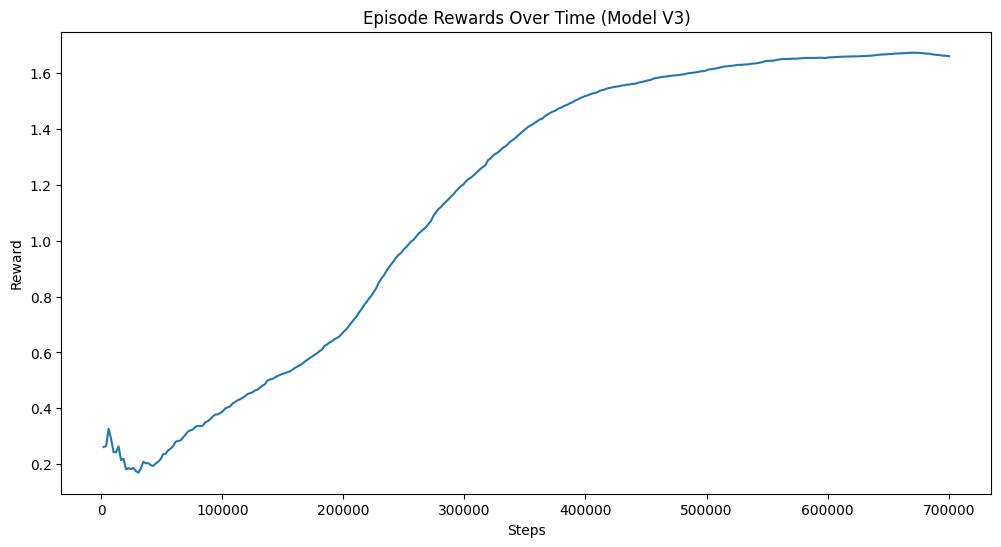

In [64]:
# Plot reward over time
plt.figure(figsize=(12, 6))
plt.plot(model_v3_log['time/iterations'] * 2048, model_v3_log['rollout/ep_rew_mean']) # Real step is iterations * 2048
plt.title('Episode Rewards Over Time (Model V3)')
plt.xlabel('Steps')
plt.ylabel('Reward')
plt.show()

The reward seems to be drawing a generally acceptable graph. However, since it is trying to converge in a place I do not want, it is certain that something is wrong, so I think I need to look at the graph more.

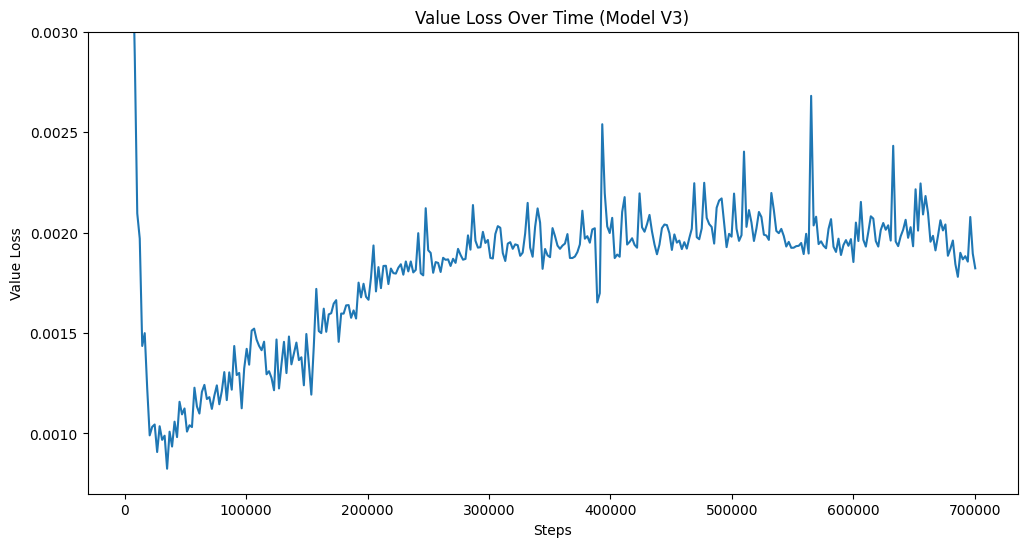

In [65]:
# Plot reward over time
plt.figure(figsize=(12, 6))
plt.plot(model_v3_log['time/iterations'] * 2048, model_v3_log['train/value_loss']) # Real step is iterations * 2048
plt.ylim(0.0007, 0.003)
plt.title('Value Loss Over Time (Model V3)')
plt.xlabel('Steps')
plt.ylabel('Value Loss')
plt.show()

Seeing that Value Loss is not reduced properly and goes up while moving sideways, I get the feeling that it is not learning properly. However, since I cannot determine it accurately, I will check the Policy Gradient Loss.

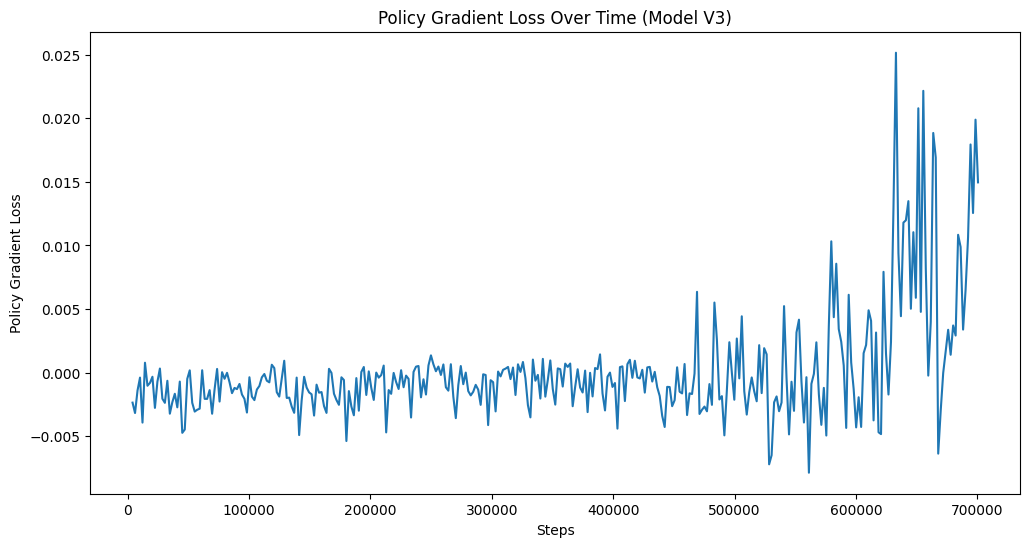

In [66]:
# Plot reward over time
plt.figure(figsize=(12, 6))
plt.plot(model_v3_log['time/iterations'] * 2048, model_v3_log['train/policy_gradient_loss']) # Real step is iterations * 2048
plt.title('Policy Gradient Loss Over Time (Model V3)')

plt.xlabel('Steps')
plt.ylabel('Policy Gradient Loss')
plt.show()

From this graph, it can be confirmed that this training did not proceed properly. From around 450,000 steps, the fluctuation of Loss increases and the absolute value also increases, which can be confirmed by the graph showing that the model is trying to update excessively compared to before when updating the policy. To confirm this more certainly, I will also check the KL value.

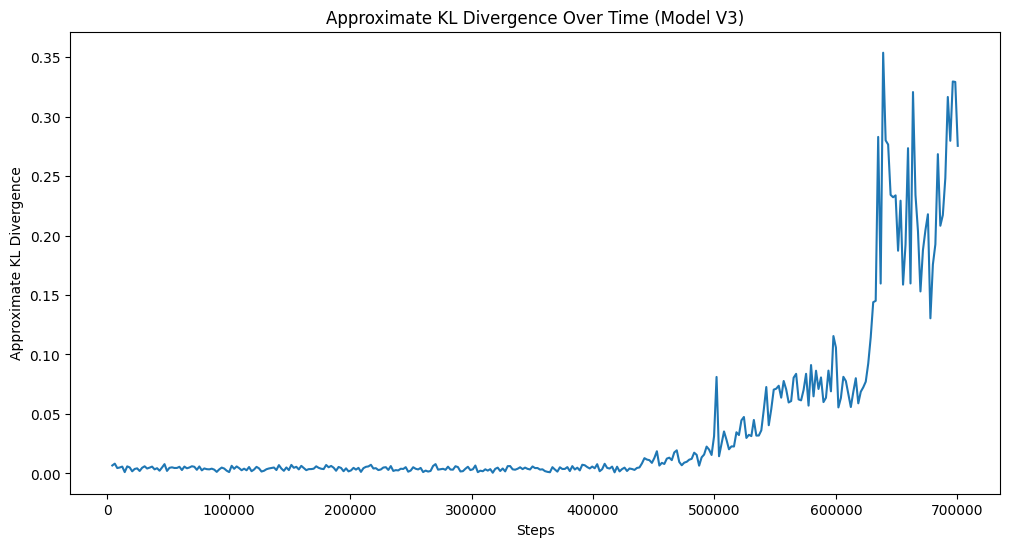

In [67]:
# Plot reward over time
plt.figure(figsize=(12, 6))
plt.plot(model_v3_log['time/iterations'] * 2048, model_v3_log['train/approx_kl']) # Real step is iterations * 2048
plt.title('Approximate KL Divergence Over Time (Model V3)')

plt.xlabel('Steps')
plt.ylabel('Approximate KL Divergence')
plt.show()

It seems to have come out as I expected. It can be confirmed that the KL value, which means the magnitude of the actual change in policy, starts to explode from around 450,000 steps, and the model is not able to get a grip and the policy is changing rapidly.

Finally, I will check how the total loss value changes.

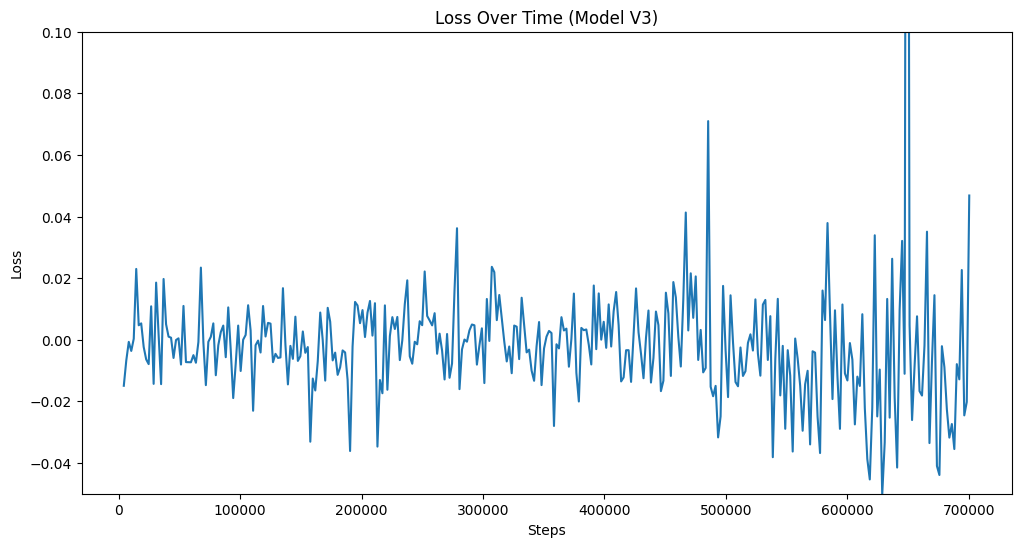

In [68]:
# Plot reward over time
plt.figure(figsize=(12, 6))
plt.plot(model_v3_log['time/iterations'] * 2048, model_v3_log['train/loss']) # Real step is iterations * 2048
plt.title('Loss Over Time (Model V3)')
plt.ylim(-0.05, 0.1)
plt.xlabel('Steps')
plt.ylabel('Loss')
plt.show()

The total loss graph shows a sideways trend without significant fluctuations, and looking at the episode reward and policy-related metrics, the actor seems to have converged to some extent and reached a plateau. However, since the value loss is not continuing to decrease as it did in the beginning, but instead increased slightly and is hovering at a low value, there are some doubts as to whether the critic has sufficiently learned the target values.

## Conclusion

Looking at the overall graph situation now, I think the model found a plateau and couldn't get out of it, so the policies became almost fixed, causing various values to jump. However, I don't think the true optimal value is here. Even simply thinking about it, Apple's stock rose 9.3 times during the train period, but looking at the current reward, it only yielded a return of e^1.6 = 4.95 times, showing a return that fell short of expectations. Even considering that the maximum buying ratio is fixed, considering that it is possible to sell when it falls and buy when it rises, this is a very disappointing result.

In [ ]:
apple_close_prices_train[-1] / apple_close_prices_train[0] # Stock price increase rate during Train period

array([9.32251094])

Due to Apple's stock rising overall, it discovered that just putting it in Apple yields profit, and strongly shows a refusal to explore further. And now, the range of action is limited to [-1, 1] to prevent stocks from being concentrated in one place when using the SoftMax function, but since there are currently only two options, such an option is not very effective and it shows that it is just pouring the maximum amount of money into Apple.

### Future Work

Based on this analysis, it seems urgent to provide the model with more data and more stock investment options. Since this model was originally designed to receive and analyze multiple stocks, it seems inevitable that it will show results that are not optimized for predicting a single stock and building a portfolio. Currently, due to the difficulty of data crawling, I could only grasp Apple stock data and one news data, but I expect that if more stock items and data are added, it will produce much better results. However, there is one more thing to be careful about here. As the input dimension increases, the number of required data is likely to increase, and it is not certain whether the 8 years of data collected now will be sufficient. However, it is really hard to get data from before that, and since most news data providers except Google News only support data from the late 2010s, I am not sure if I can get the data I want.

And data refinement may become more important. Currently, the number of news data is so large that it is almost impossible to crawl news data, so I embedded the titles. Although I filtered by title length being above a certain level, there is no guarantee that it is a meaningful title. Also, for the embedding method, I used Google's embedding, but even if it shows SOTA-level performance, it is not an embedding specialized for stocks, so the model may have difficulty distinguishing it. Also, Apple's news data was crawled using keywords from GDELT, but there is no guarantee that the data is related to stocks, and it is highly likely that such information contaminated the embedding when simply scraping journals such as iPhone usage tips. If I can use the news data provided by yfinance, it seems highly likely that I can secure better quality data. However, it is not certain whether the amount of news it provides is the amount I need.